# Week 6 — Classification I: Logistic Regression and K-Nearest Neighbours

## Applied to the project: sleep and depression in adolescents

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

**Classification** means predicting a category, using examples where the right answer is already known. This notebook follows the Week 6 lecture notebook step by step, with the project data in place of the lecturer's student example: **predicting whether an adolescent is above the BDI-II threshold, based on their average sleep hours and their sleep quality index.**

Two features are used, as in the lecture notebook, so that the data and the decision boundaries can be drawn in a two-dimensional plot. The models that use all seven features are in `logistic_regression.ipynb` and `knn.ipynb`.

The terms used throughout:

| Term | Meaning | In this notebook |
|---|---|---|
| **Observation** | One row of the data: one case | One adolescent |
| **Features** (`X`) | The information used to make the prediction (the inputs) | Average sleep hours, sleep quality index |
| **Target** (`y`) | The thing to predict (the answer) | Depressed (`1`) or not depressed (`0`) |
| **Model** | A rule, learned from data, that turns features into a prediction | Logistic Regression, KNN |
| **Training** | Letting the model learn from examples where the answer is known | `model.fit(...)` |

## The two methods in one sentence each

- **Logistic Regression** draws a dividing line between the groups and uses it to estimate the *probability* that an adolescent is above the threshold.
- **K-Nearest Neighbours (KNN)** looks at the most similar adolescents in the training data and goes with the majority outcome ("ask the neighbours").

**Learning goals (from Week 6), applied here**
- Train Logistic Regression and KNN classifiers.
- Explain why scaling matters for KNN.
- Compare test accuracy and visualise decision boundaries.

## 1. Import the libraries

`RANDOM_STATE = 42` fixes the random seed. Some steps (such as splitting the data) involve random choices; fixing the seed makes them the same on every run, so everyone in the group gets the same results. The number 42 itself is arbitrary.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

## 2. Load the project dataset

The data are in `data/raw/Mental_health.csv`. Each **row** is one adolescent and each **column** is one piece of information about them. This notebook uses three columns:

- **Features (`X`)**:
  - `avg_sleep_hours`: average hours of sleep per night.
  - `sleep_quality_index`: a score from 1 to 6 built from four questions about sleep problems. A higher score means more sleep problems.
- **Target (`y`)**: `depressed` (`1` = BDI-II total of 14 or above, `0` = below).

`df.head()` shows the first five rows, to check that the data loaded correctly.

In [13]:
df = pd.read_csv("../data/raw/Mental_health.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (4810, 10)


,subject_id,sex,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours,bdi_total,depressed
0,1,Boy,3.333,4.64,2.25,8.36,4.58,1.92,6,0
1,2,Girl,3.333,4.07,2.50,7.31,5.42,2.25,7,0
2,3,Boy,3.333,4.07,2.00,8.75,5.50,2.62,27,1
3,4,Boy,4.333,6.07,1.50,8.17,6.62,3.96,22,1
4,5,Boy,1.667,0.50,2.50,8.88,4.12,1.79,3,0


## 3. Explore the data

The scatter plot shows the two features, coloured by the target. The table underneath counts the adolescents in each class.

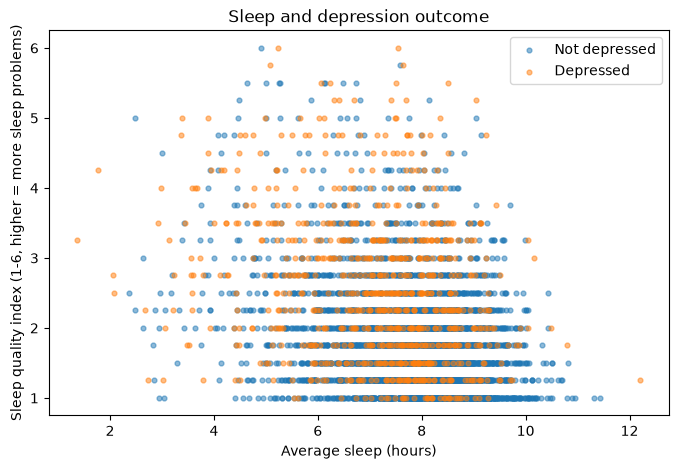

depressed
Not depressed    0.836
Depressed        0.164
Name: proportion, dtype: float64


depressed
Not depressed    4023
Depressed         787
Name: count, dtype: int64

In [14]:
class_names = {0: "Not depressed", 1: "Depressed"}

fig, ax = plt.subplots(figsize=(8, 5))
for label, name in class_names.items():
    subset = df[df["depressed"] == label]
    ax.scatter(subset["avg_sleep_hours"], subset["sleep_quality_index"], label=name, s=12, alpha=0.5)

ax.set_xlabel("Average sleep (hours)")
ax.set_ylabel("Sleep quality index (1-6, higher = more sleep problems)")
ax.set_title("Sleep and depression outcome")
ax.legend()
plt.show()

print(df["depressed"].value_counts(normalize=True).rename(index=class_names).round(3))
df["depressed"].value_counts().rename(index=class_names)

### What the plot and counts show

- **The classes are imbalanced:** 787 of the 4,810 adolescents (16.4%) are above the threshold and 4,023 (83.6%) are below it.
- **The two classes overlap heavily.** Adolescents above the threshold are more common towards the upper left (shorter sleep, more sleep problems), but they are found across the whole plot. Two adolescents with the same sleep profile can have different outcomes.
- The sleep quality index only takes certain values (steps of 0.25), which is why the points fall in horizontal rows.
- Because of the imbalance, a "model" that always predicts "Not depressed" would already be 83.6% accurate. This number is the baseline for everything below.

## 4. Define `X` and `y`, then split the data

`X` contains the input features (average sleep hours and sleep quality index). `y` contains the target (depressed or not).

### What does `stratify=y` do?

The split is random. By chance, a random split could put a different share of depressed adolescents in the training set and in the test set, which would make the comparison unfair.

**Stratification** prevents this. It means "split randomly, but keep the proportion of each class about the same in both sets". Since 16.4% of all adolescents are above the threshold, about 16.4% of the training set and about 16.4% of the test set will be too. This matters more when one class is small, as it is here.

The cell below prints the proportions as a check. `random_state=RANDOM_STATE` makes the split reproducible.

This notebook keeps the lecture notebook's split (25% test, stratified). The other project notebooks use a 20% test set, so the test sets and scores are not directly comparable with them.

In [15]:
X = df[["avg_sleep_hours", "sleep_quality_index"]]
y = df["depressed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

# Share of each class in each group; stratify=y keeps these similar
pd.DataFrame({
    "All adolescents": y.value_counts(normalize=True),
    "Training set": y_train.value_counts(normalize=True),
    "Test set": y_test.value_counts(normalize=True)
}).rename(index=class_names).round(3)

Training observations: 3607
Test observations: 1203


,All adolescents,Training set,Test set
depressed,,,
Not depressed,0.836,0.836,0.836
Depressed,0.164,0.164,0.164


## 5. Train a Logistic Regression classifier

### The idea

Despite its name, Logistic Regression is used for **classification**. It works in two steps:

1. It combines the features into a single score, giving each feature a weight. The model learns these weights from the training data.
2. It converts that score into a **probability** between 0 and 1 (using the S-shaped sigmoid curve): the model's estimated chance that the adolescent is above the threshold.

To get a final answer, a **threshold** is applied to the probability. By convention it is 0.5, so a probability of 0.5 or more is classified as depressed (`1`) and anything lower as not depressed (`0`). This is a choice, not a rule of nature: a lower threshold would flag more adolescents.

Geometrically, with two features the model draws a **straight line** through the plot: adolescents on one side are predicted to be above the threshold, those on the other side below it.

### Scaling and pipelines

Average sleep ranges from about 1 to 12 hours and the sleep quality index from 1 to 6. **Scaling** with `StandardScaler` rewrites each feature so that it is centred on 0 with a comparable spread. This is not strictly necessary for Logistic Regression, but it helps the learning process and makes the weights comparable.

A **pipeline** chains the steps: first scale, then classify. The scaler learns its mean and standard deviation from the training data only. Using the test set for this would leak information about the "unseen" data into the model (*data leakage*, from the preprocessing lecture).

### The key commands below

- `fit(X_train, y_train)`: the model learns from the training examples.
- `predict(X_test)`: the model gives a predicted class (0 or 1) for each test adolescent.
- `predict_proba(X_test)`: the model gives the probabilities behind those predictions. Column `[:, 1]` is the probability of being depressed.
- **Accuracy**: the share of test adolescents classified correctly.

In [16]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)
)

log_reg.fit(X_train, y_train)

log_predictions = log_reg.predict(X_test)
log_probabilities = log_reg.predict_proba(X_test)[:, 1]

weights = pd.Series(log_reg[-1].coef_[0], index=X.columns).round(3)
print("Learned weights (for standardised features):")
print(weights.to_string())

print("\nFirst 10 predicted classes:", log_predictions[:10])
print("First 10 probabilities of being depressed:", np.round(log_probabilities[:10], 2))
print("Test accuracy:", round(accuracy_score(y_test, log_predictions), 3))
print("Baseline (always 'Not depressed'):", round((y_test == 0).mean(), 3))
print("Adolescents predicted as depressed:", int(log_predictions.sum()), "of", len(y_test),
      f"(actually depressed: {int(y_test.sum())})")

Learned weights (for standardised features):
avg_sleep_hours       -0.258
sleep_quality_index    0.652

First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
First 10 probabilities of being depressed: [0.11 0.09 0.07 0.07 0.07 0.13 0.13 0.21 0.2  0.07]
Test accuracy: 0.835
Baseline (always 'Not depressed'): 0.836
Adolescents predicted as depressed: 39 of 1203 (actually depressed: 197)


### What the results show

- **Weights:** the sleep quality index has a positive weight (0.65): more sleep problems raise the predicted probability. Average sleep hours has a negative weight (−0.26): more sleep lowers it. The index has the larger weight, so it matters more in this model.
- **The first ten probabilities are all low** (0.07 to 0.21), so all ten adolescents are classified as not depressed.
- **Test accuracy is 0.835, slightly below the baseline of 0.836.** The model is no more accurate than always predicting "Not depressed".
- **It flags only 39 of the 1,203 test adolescents**, although 197 are actually above the threshold. With a 0.5 threshold and overlapping classes, the probability rarely reaches 0.5.

### Interpret one prediction

A probability and a predicted class are not the same thing. The class is obtained by applying the threshold to the probability. A probability of 0.51 and one of 0.99 both give "Depressed", but the model is far more confident in the second case.

The cell below shows one adolescent from the test set: their features, the actual class, the model's probability and the model's final prediction. The index `i` can be changed to inspect another test adolescent. For example, `i = 10` is an adolescent who is above the threshold but receives a probability of only about 0.20, so the model misses them.

In [17]:
i = 0
print("Features:")
display(X_test.iloc[[i]])
print("Actual class:", class_names[int(y_test.iloc[i])])
print("Probability of being depressed:", round(float(log_probabilities[i]), 3))
print("Predicted class at threshold 0.5:", class_names[int(log_predictions[i])])

Features:


,avg_sleep_hours,sleep_quality_index
2424,9.62,2.0


Actual class: Not depressed
Probability of being depressed: 0.106
Predicted class at threshold 0.5: Not depressed


## 6. Train a K-Nearest Neighbours classifier

### The idea

KNN is based on a simple principle: **similar adolescents tend to have similar outcomes**. To predict for a new adolescent:

1. Measure how far they are from every adolescent in the training set (using sleep hours and the sleep quality index).
2. Pick the `k` closest ones, their "nearest neighbours". Here `k = 5`.
3. Look at the neighbours' outcomes and take a **majority vote**. If 4 of the 5 neighbours are not depressed, predict "Not depressed".

KNN does not learn weights or draw a line. It stores the training data and looks things up when asked. The choice of `k` is explored in section 9.

### Why scaling matters here

"Distance" depends on the units of the features. Average sleep hours has a standard deviation of about 1.27 and the sleep quality index about 0.85, so without scaling a typical difference in sleep hours would count for more than a typical difference in sleep quality. The gap is smaller than in the lecture example (attendance against study hours), but the principle is the same: scaling puts both features on a comparable footing, so each contributes fairly. As before, the pipeline fits the scaler on the training data only.

In [18]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)
knn_predictions = knn.predict(X_test)

print("First 10 predicted classes:", knn_predictions[:10])
print("Test accuracy:", round(accuracy_score(y_test, knn_predictions), 3))
print("Adolescents predicted as depressed:", int(knn_predictions.sum()), "of", len(y_test))

First 10 predicted classes: [0 0 0 0 0 0 0 0 0 0]
Test accuracy: 0.81
Adolescents predicted as depressed: 102 of 1203


## 7. Compare the two models

Both models are evaluated on exactly the same test adolescents, so the comparison is fair. **Accuracy** is the proportion of test observations classified correctly. The baseline (always predicting "Not depressed") is added to the table for reference.

In [19]:
results = pd.DataFrame({
    "Model": ["Baseline (always 'Not depressed')", "Logistic Regression", "KNN (k=5)"],
    "Test accuracy": [
        (y_test == 0).mean(),
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, knn_predictions)
    ],
    "Depressed adolescents caught": [
        0,
        int(((log_predictions == 1) & (y_test == 1)).sum()),
        int(((knn_predictions == 1) & (y_test == 1)).sum())
    ]
}).sort_values("Test accuracy", ascending=False).round(3)

print("Depressed adolescents in the test set:", int(y_test.sum()))
results

Depressed adolescents in the test set: 197


,Model,Test accuracy,Depressed adolescents caught
0,Baseline (always 'Not depressed'),0.836,0
1,Logistic Regression,0.835,19
2,KNN (k=5),0.810,35


### What the comparison shows

- **Neither model beats the baseline on accuracy:** baseline 0.836, Logistic Regression 0.835, KNN 0.810.
- **KNN is less accurate but catches more real cases:** 35 of the 197 depressed adolescents, against 19 for Logistic Regression. It does this by flagging more adolescents overall (102 against 39), so it also raises more false alarms.
- Both models miss more than 80% of the adolescents who are above the threshold.

### Accuracy is just the first step

Accuracy gives one number for "how often was the model right?", but it hides important details. This dataset shows the problems the lecture notebook warns about:

- **What kinds of mistakes does the model make?** Predicting "Not depressed" for an adolescent who is above the threshold and predicting "Depressed" for one who is below it are both errors, but they are not equally costly. In a screening setting, missing an adolescent who needs support is probably worse than flagging one who does not.
- **Is the model good on the rarer class?** Only 16.4% of the adolescents are above the threshold. A model that always predicts "Not depressed" is 83.6% accurate and never identifies a single one of them.
- **Can a single test set be trusted?** One lucky or unlucky split can change the accuracy. A result should be checked for stability.

The confusion matrix, precision, recall and cross-validation answer these questions. They are applied to the project data in `evaluation.ipynb` and `model_comparison.ipynb`. The accuracy values above are a first, rough comparison.

## 8. Visualise the decision boundaries

A **decision boundary** is the border between the region where a model predicts "Not depressed" and the region where it predicts "Depressed". To draw it, the model predicts a class for every point on a fine grid across the plot, and the background is coloured by the answer. The dots are the training adolescents.

How to read the plots:
- A dot sitting in a region of a different colour is an adolescent the model gets wrong.
- The boundary shows *how the model thinks*, not just how well it scores.

What to expect:
- Logistic Regression produces a **straight-line** boundary.
- KNN can produce a **curvy, irregular** boundary that follows local neighbourhoods.

These plots are for understanding model behaviour; performance should still be evaluated on held-out data.

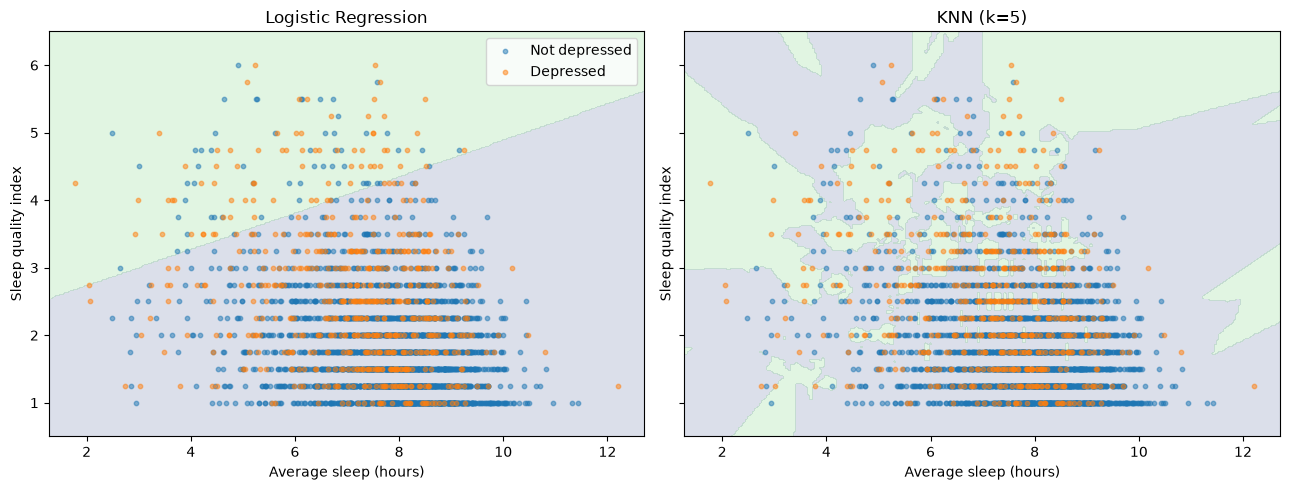

In [20]:
def plot_decision_boundary(model, X_train, y_train, title, ax):
    x_min, x_max = X_train["avg_sleep_hours"].min() - 0.5, X_train["avg_sleep_hours"].max() + 0.5
    y_min, y_max = X_train["sleep_quality_index"].min() - 0.5, X_train["sleep_quality_index"].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )
    grid = pd.DataFrame({
        "avg_sleep_hours": xx.ravel(),
        "sleep_quality_index": yy.ravel()
    })
    zz = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5])
    for label, name in class_names.items():
        subset = X_train.loc[y_train == label]
        ax.scatter(subset["avg_sleep_hours"], subset["sleep_quality_index"], label=name, s=10, alpha=0.5)
    ax.set_xlabel("Average sleep (hours)")
    ax.set_ylabel("Sleep quality index")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
plot_decision_boundary(log_reg, X_train, y_train, "Logistic Regression", axes[0])
plot_decision_boundary(knn, X_train, y_train, "KNN (k=5)", axes[1])
axes[0].legend()
plt.tight_layout()
plt.show()

### What the boundaries show

In both plots the green region is where the model predicts "Depressed" and the grey region is where it predicts "Not depressed".

- **Logistic Regression** draws one straight line. Only the upper-left corner (short sleep combined with a high sleep quality index) is predicted as depressed. Few adolescents lie there, which is why the model flags so few.
- **KNN (k = 5)** produces an irregular boundary with many small green patches scattered through the plot, each following a few nearby depressed adolescents. The large green areas at the edges are regions with almost no data, where the prediction rests on a handful of distant neighbours.
- **Orange dots (depressed) lie throughout the grey region in both plots.** These are the adolescents the models miss. The two classes overlap so much on these features that no boundary, straight or curved, separates them well.

## 9. What changes when `k` changes?

In KNN, `k` is the number of neighbours that vote. It is a setting chosen by the analyst, not something the model learns.

- **Small `k` (e.g. 1)**: the prediction depends on just one neighbour, so the model reacts to every individual adolescent, including unusual ones and random noise. The boundary becomes very irregular. The model can fit the training data almost perfectly but may not work well on new adolescents. This is **overfitting**.
- **Large `k` (e.g. 20)**: many neighbours vote, so individual unusual adolescents have little influence. The boundary becomes smooth, but if `k` is too large the model may ignore genuine local patterns (**underfitting**).

KNN is trained with three values of `k`. Training accuracy is shown next to test accuracy, because the gap between them is the sign of overfitting.

In [21]:
k_values = [1, 5, 20]
knn_models = {}
k_results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    knn_models[k] = model
    k_results.append({
        "k": k,
        "Training accuracy": model.score(X_train, y_train),
        "Test accuracy": accuracy_score(y_test, predictions),
        "Predicted as depressed": int(predictions.sum())
    })

print("Baseline test accuracy (always 'Not depressed'):", round((y_test == 0).mean(), 3))
pd.DataFrame(k_results).round(3)

Baseline test accuracy (always 'Not depressed'): 0.836


,k,Training accuracy,Test accuracy,Predicted as depressed
0,1,0.919,0.747,201
1,5,0.864,0.810,102
2,20,0.846,0.823,58


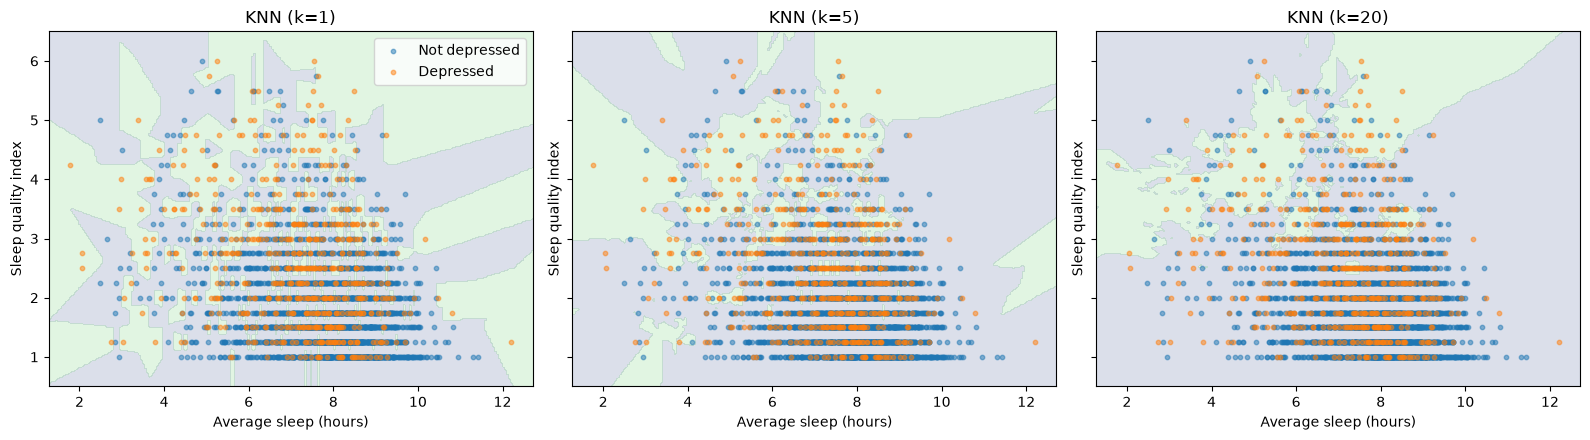

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, k in zip(axes, k_values):
    plot_decision_boundary(knn_models[k], X_train, y_train, f"KNN (k={k})", ax)
axes[0].legend()
plt.tight_layout()
plt.show()

### What changing `k` shows

- **k = 1:** training accuracy is 0.922 but test accuracy only 0.753, well below the baseline of 0.836. The boundary is the most fragmented of the three. This is **overfitting**: the model follows individual adolescents and noise. Training accuracy is not 1.000 because many adolescents share exactly the same two feature values but have different outcomes.
- **k = 5:** the gap narrows (0.866 training, 0.810 test) and the boundary has fewer patches.
- **k = 20:** the smoothest boundary and the best test accuracy of the three (0.823), with training accuracy close behind (0.845). It is still below the baseline.
- **As k grows, the model flags fewer adolescents:** 196 with k = 1, 102 with k = 5 and 58 with k = 20. With a larger k, a "Depressed" prediction needs most of the neighbours to be depressed, which is rare when only 16.4% are. Accuracy rises mainly because the model moves towards always predicting "Not depressed".
- The value of k should not be chosen from these test scores. `knn.ipynb` and `evaluation.ipynb` use validation data and cross-validation for that.

## Key takeaways

### For the project

- With two sleep features, **neither Logistic Regression nor KNN is more accurate than always predicting "Not depressed"** (baseline 0.836).
- **Sleep is related to the outcome, but weakly:** more sleep problems and less sleep raise the predicted probability, yet adolescents above and below the threshold overlap too much for these two features to separate them.
- **Accuracy is misleading here** because only 16.4% of adolescents are above the threshold. Recall and precision, used in the later notebooks, are the measures that matter for this question.
- **KNN with a small `k` overfits**; a larger `k` gives a smoother boundary and better test accuracy, but flags very few adolescents.
- The models with all seven features are in `logistic_regression.ipynb` and `knn.ipynb`.

### Logistic Regression vs KNN

| | **Logistic Regression** | **K-Nearest Neighbours (KNN)** |
|---|---|---|
| **Main idea** | Learns a weight for each feature and combines them into a score | Finds the `k` most similar training observations and takes a majority vote |
| **What is learned** | Weights (one per feature), learned during training | Nothing: it stores the training data and looks things up at prediction time |
| **Output** | A probability of the positive class, then a class using a threshold (0.5 by convention) | A class from a vote among the neighbours |
| **Decision boundary** | A straight line (in 2 features) | Can be curvy and irregular, following local neighbourhoods |
| **Setting chosen by the analyst** | The threshold (and other settings not used here) | `k`, the number of neighbours |
| **Effect of that setting** | Moving the threshold changes how cautious the model is about predicting "Depressed" | Small `k`: irregular boundary, risk of overfitting. Large `k`: smooth boundary, risk of underfitting |
| **Scaling the features** | Helpful, but not essential | Important: distances depend on units, so unscaled features can dominate |
| **Interpretability** | The weights show how each feature pushes the prediction up or down | Easy to explain ("adolescents like this one were not depressed"), but there are no weights to inspect |
| **Prediction speed** | Fast | Slower on large datasets, since it compares against the stored training data |